<h1>Notebook para Strepto2 </h1>

In [1]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import hamming
import gudhi as gd
import seaborn as sns
from statistics import mode
import multiprocessing
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
import gudhi as gd
# from scipy.spatial.distance import hamming
import plotly.graph_objs as go
import networkx as nx
import plotly.graph_objects as go
import plotly.io as pio
from networkx.utils import not_implemented_for, pairwise
from concurrent.futures import ThreadPoolExecutor, as_completed
import plotly
import plotly.express as px
from module_functions import *

<h2>Se extrae la información </h2>

In [2]:
info=pd.read_csv('data/pscplos1246.blast',sep='\t',header=None)
names=pd.read_csv('data/Actinos.ids',sep='\t',dtype='object',header=None)

<h2>Se crean los data frames</h2>

In [3]:
df_by_pathway,df_by_pathway_drop_duplicate,representative_genomes=get_df_by_pathway(info)

In [14]:
print('n genomas:',len(df_by_pathway['3PGA_AMINOACIDS'].index))
cont=0
cont2=0
for i,j in df_by_pathway.items():
    cont2+=len(j.columns)
    cont+=1
    print(i)
print('n rutas',cont)
print('n genes',cont2)

n genomas: 1244
3PGA_AMINOACIDS
PYR_THR_AA
ALPHAKETOGLUTARATE_AMINOACIDS
OXALACETATE_AMINOACIDS
E4P_AMINO_ACIDS
Glycolysis
calcium_dependent_antibiotic
polyketide
R5P_AMINOACIDS
TCA
n rutas 10
n genes 44


<h2> Se crea el complejo simplicial</h2>

In [4]:
complex_pathways=get_complex_by_pathways(df_by_pathway_drop_duplicate)

In [5]:
complex_pathways['R5P_AMINOACIDS']
for i in complex_pathways.keys():
    contador=0
    for j in complex_pathways[i][0]:
        if j[0]==1:
            contador+=1
    print(i,contador)

R5P_AMINOACIDS 25
polyketide 0
Glycolysis 11
TCA 61
calcium_dependent_antibiotic 0
E4P_AMINO_ACIDS 167
OXALACETATE_AMINOACIDS 395
3PGA_AMINOACIDS 32
ALPHAKETOGLUTARATE_AMINOACIDS 431
PYR_THR_AA 287


In [12]:
#plot_all_bar_code_pathways(complex_pathways)

In [35]:
import matplotlib.pyplot as plt
plt.switch_backend('Agg') 

# Datos de las rutas metabólicas para cada linaje taxonómico
data = {
    "Cyanobacteriota": {
        "TCA": np.log(7+1),
        "R5P_AMINOACIDS": np.log(67+1),
        "OXALACETATE_AMINOACIDS": np.log(39+1),
        "3PGA_AMINOACIDS": np.log(7+1),
        "Glycolysis": np.log(11+1),
        "calcium-dependent-antibiotic": np.log(0+1),
        "E4P_AMINO_ACIDS": np.log(80+1),
        "polyketide": np.log(1+0),
        "PYR_THR_AA": np.log(1+44),
        "ALPHAKETOGLUTARATE_AMINOACIDS": np.log(1+66)
    },
    "Ornithinimicrobiaceae": {
        "Glycolysis": np.log(1+1),
        "OXALACETATE_AMINOACIDS": np.log(1+2),
        "PPP": np.log(1+2),
        "ALPHAKETOGLUTARATE_AMINOACIDS": np.log(1+3),
        "TCA": np.log(1+1),
        "R5P_AMINOACIDS": np.log(1+1),
        "3PGA_AMINOACIDS": np.log(1+1),
        "PYR_THR_AA": np.log(1+2),
        "E4P_AMINO_ACIDS": np.log(1+0)
    },
    "Pseudomonas": {
        "R5P_AMINOACIDS": np.log(1+8),
        "Glycolysis": np.log(1+2),
        "E4P_AMINO_ACIDS": np.log(1+6),
        "OXALACETATE_AMINOACIDS": np.log(1+54),
        "TCA": np.log(1+4),
        "ALPHAKETOGLUTARATE_AMINOACIDS": np.log(1+46),
        "polyketide": np.log(1+0),
        "3PGA_AMINOACIDS": np.log(1+9),
        "PYR_THR_AA": np.log(1+51),
        "calcium-dependent-antibiotic": np.log(1+0)
    },
    "Streptosporangiaceae 1": {
        "E4P_AMINO_ACIDS": np.log(1+119),
        "3PGA_AMINO_ACIDS": np.log(1+133),
        "OXALACETATE_AMINO_ACIDS": np.log(1+174),
        "TCA": np.log(1+100),
        "Glycolysis": np.log(1+111),
        "ALPHAKETOGLUTARATE_AMINOACIDS": np.log(1+113),
        "PPP": np.log(1+97),
        "PYR_THR_AA": np.log(1+116),
        "R5P_AMINO_ACIDS": np.log(1+71)
    },
    "Streptosporangiaceae 2": {
        '3PGA_AMINOACIDS': np.log(1+32),
        "PYR_THR_AA": np.log(1+287),
        "ALPHAKETOGLUTARATE_AMINOACIDS": np.log(1+431),
        "OXALACETATE_AMINOACIDS": np.log(1+395),
        "E4P_AMINO_ACIDS": np.log(1+167),
        "Glycolysis": np.log(1+11),
        "calcium_dependent_antibiotic": np.log(1+0),
        "polyketide": np.log(1+0),
        "R5P_AMINOACIDS": np.log(1+25),
        "TCA": np.log(1+61)
    }
}

# Todas las rutas metabólicas posibles
metabolic_paths

# Paleta de colores suave pero contrastante
colors = {
    "Cyanobacteriota": '#4C72B0',  # Azul suave
    "Ornithinimicrobiaceae": '#FF8C00',  # Naranja suave
    "Pseudomonas": '#2CA02C',  # Verde suave
    "Streptosporangiaceae 1": '#E31A1C',  # Rojo suave
    "Streptosporangiaceae 2": '#9467BD'   # Púrpura suave
}

# Configurar la gráfica
fig, ax = plt.subplots(figsize=(12, 8))

# Ancho de las barras
bar_width = 0.15
index = np.arange(len(metabolic_paths))  # Índices para las barras
offsets = np.array([bar_width * i for i in range(len(data))])  # Desplazamientos para las barras

# Para cada linaje taxonómico, agregar las barras
for i, (taxon, color) in enumerate(colors.items()):
    # Obtener valores del linaje actual, asegurando que tenga el mismo tamaño que las rutas metabólicas
    values = [data[taxon].get(path, 0) for path in metabolic_paths]
    ax.bar(index + offsets[i], values, bar_width, label=taxon, color=color)

# Ajustar las etiquetas del eje X para que estén centradas con respecto a las barras
ax.set_xlabel('Rutas metabólicas')
ax.set_ylabel('Logaritmo del número de 1-hoyos más uno')


# Alinear correctamente las posiciones de las etiquetas en el eje X
ax.set_xticks(index + bar_width * (len(data) - 1) / 2)  # Alineación correcta de las etiquetas
ax.set_xticklabels(metabolic_paths, rotation=45, ha='right')  # Ajuste para evitar superposición

# Añadir las líneas tenues paralelas al eje Y
ax.grid(True, axis='y', linestyle='--', linewidth=0.5, color='gray')

# Añadir la leyenda
ax.legend(title='Linajes taxonómicos')

# Ajuste para mejorar el layout
plt.tight_layout()

# Mostrar la gráfica
plt.show()
plt.savefig('1_hoyos_por_ruta.svg',format='svg')

In [33]:
metabolic_paths.sort()

In [34]:
metabolic_paths

['3PGA_AMINOACIDS',
 'ALPHAKETOGLUTARATE_AMINOACIDS',
 'E4P_AMINO_ACIDS',
 'Glycolysis',
 'OXALACETATE_AMINOACIDS',
 'PPP',
 'PYR_THR_AA',
 'R5P_AMINOACIDS',
 'TCA',
 'calcium-dependent-antibiotic',
 'polyketide']

<h2>Se buscan los uno hoyos</h2>

In [13]:
holes_no_names,holes_with_names,holes_per_filt_lvl=get_holes_by_pathways(complex_pathways,df_by_pathway_drop_duplicate)

se buscan ciclos en el tiempo 3.0 para OXALACETATE_AMINOACIDS
Se encontró el ciclo [9, 6, 1, 0] en el tiempo 2.0 para OXALACETATE_AMINOACIDS
se buscan ciclos en el tiempo 6.0 para OXALACETATE_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para ALPHAKETOGLUTARATE_AMINOACIDS
se buscan ciclos en el tiempo 4.0 para PYR_THR_AA
se buscan ciclos en el tiempo 2.0 para Glycolysis
Se encontró el ciclo [1, 12, 6, 5, 4, 3, 2] en el tiempo 1.0 para Glycolysis
Se encontró el ciclo [18, 3, 6, 0] en el tiempo 5.0 para OXALACETATE_AMINOACIDS
Terminó la ruta  OXALACETATE_AMINOACIDS
Se encontró el ciclo [19, 14, 10, 5] en el tiempo 1.0 Terminó la ruta  Glycolysis
para ALPHAKETOGLUTARATE_AMINOACIDS
Se encontró el ciclo [19, 8, 6, 5] en el tiempo 1.0 para ALPHAKETOGLUTARATE_AMINOACIDS
se buscan ciclos en el tiempo 3.0 para ALPHAKETOGLUTARATE_AMINOACIDS
se buscan ciclos en el tiempo 4.0 para R5P_AMINOACIDS
Se encontró el ciclo [3, 7, 4, 0] en el tiempo 3.0 para R5P_AMINOACIDS
Terminó la ruta  R5P_AMINOACIDS
S

In [14]:
resum=get_resum_df(df_by_pathway,representative_genomes,names,complex_pathways,holes_with_names)
resum

/opt/conda/envs/TDA/lib/python3.7/site-packages/pandas/core/internals/blocks.py:937: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr_value = np.asarray(value)


,num_columnas,num_hoyos,ciclos,ciclos por genero,duración hoyos
OXALACETATE_AMINOACIDS,16,2,"[[Ornithinimicrobium sp. na, Ornithinimicrobiu...","[[Ornithinimicrobium, Ornithinimicrobium, Orni...",[1.0]
E4P_AMINO_ACIDS,17,0,[],[],[]
ALPHAKETOGLUTARATE_AMINOACIDS,11,3,"[[Ornithinimicrobium cerasi USBA17B2, Ornithin...","[[Ornithinimicrobium, Ornithinimicrobium, Orni...",[1.0]
﻿Glycolysis,1,0,[],[],[]
PYR_THR_AA,10,2,"[[Ornithinimicrobium sp. na, Ornithinimicrobiu...","[[Ornithinimicrobium, Ornithinimicrobium, Seri...",[1.0]
Glycolysis,10,1,"[[[Serinicoccus sp. CUA-874 CUA-874, Ornithini...","[[[Serinicoccus, Ornithinimicrobium], Ornithin...",[1.0]
R5P_AMINOACIDS,9,1,"[[Serinicoccus sp. CNJ-927 CNJ-927, Ornithinim...","[[Serinicoccus, Ornithinimicrobium, [Ornithini...",[1.0]
TCA,11,1,"[[Serinicoccus hydrothermalis JLT9, [Serinicoc...","[[Serinicoccus, [Serinicoccus, Ornithinimicrob...",[1.0]
PPP,8,2,"[[Ornithinimicrobium cerasi USBA17B2, [Ornithi...","[[Ornithinimicrobium, [Ornithinimicrobium, Orn...",[1.0]
3PGA_AMINOACIDS,5,1,"[[Ornithinimicrobium sp. na, Ornithinimicrobiu...","[[Ornithinimicrobium, Ornithinimicrobium, [Orn...",[1.0]


<h2>Se ven los elementos que hacen el hoyo</h2>

In [15]:
df_pathway_make_hole=get_df_by_pathway_make_hole(df_by_pathway_drop_duplicate,holes_with_names)

In [16]:
traduced_df(df_pathway_make_hole['R5P_AMINOACIDS'][0],names)


,histidinol_dehydrogenase,phosphoribosyl_AMP_cyclohydrolase,histidinol_phosphatase,ATP_phosphoribosyltransferase,histidinolphosphate_aminotransferase,imidazoleglycerol_phosphate_dehydratase,imidazole_glycerol_phosphate_synthase_H,ribosephosphate_pyrophosphokinase,phosphoribosyl_isomerase_A
R5P_AMINOACIDS,,,,,,,,,
Serinicoccus sp. CNJ-927 CNJ-927,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,2
Ornithinimicrobium sp. na,1.0,0.0,1.0,0.0,1.0,1.0,2.0,0.0,2
Ornithinimicrobium humiphilum DSM 12362,1.0,0.0,1.0,1.0,2.0,1.0,2.0,1.0,2
Serinicoccus chungangensis CD08_5,1.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0,2


<h2>Se buscan uno hoyos pero al separar por genero y ruta metabólica</h2>

In [17]:
df_by_genus_pathway,df_by_genus_pathway_drop_duplicate,representative_genomes_genus_pathway=get_df_by_genus_pathway(df_by_pathway,names)
complex_genus_pathways=get_complex_by_pathways(df_by_genus_pathway_drop_duplicate)

In [18]:
traduced_df(df_by_genus_pathway['Serinicoccus_ALPHAKETOGLUTARATE_AMINOACIDS'],names)

,Glutamine_2-oxoglutarate,Glutamate_5_kinase,Glutamate-5-semialdehyde_dehydrogenase,Acetylornithine_aminotransferase,glutamate_synthase,glutamate,Argininosuccinate,argininosuccinate_lyase,Pyrroline-5-carboxylate_reductase,Glutamine_synthetase,Ornithine_carbamoyltransferase
Serinicoccus_ALPHAKETOGLUTARATE_AMINOACIDS,,,,,,,,,,,
Serinicoccus chungangensis CD08_5,1.0,1.0,1.0,6.0,1.0,0.0,1.0,1.0,1.0,3,1.0
Serinicoccus hydrothermalis JLT9,1.0,1.0,1.0,8.0,2.0,0.0,1.0,1.0,1.0,3,1.0
Serinicoccus sp. CUA-874 CUA-874,1.0,1.0,1.0,5.0,1.0,0.0,1.0,1.0,1.0,4,1.0
Serinicoccus sp. CNJ-927 CNJ-927,1.0,0.0,1.0,7.0,1.0,0.0,1.0,1.0,1.0,4,1.0


In [19]:
holes_genus_no_names,holes_genus_with_names,holes_genus_per_filt_lvl=get_holes_by_pathways(complex_genus_pathways,df_by_genus_pathway_drop_duplicate)

se buscan ciclos en el tiempo 6.0 para Ornithinimicrobium_OXALACETATE_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para Ornithinimicrobium_ALPHAKETOGLUTARATE_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para Ornithinimicrobium_PPP
Se encontró el ciclo [11, 3, 5, 2] en el tiempo 1.0 para Ornithinimicrobium_PPP
Terminó la ruta  Ornithinimicrobium_PPP
Se encontró el ciclo [15, 10, 6, 1] en el tiempo 1.0 para Ornithinimicrobium_ALPHAKETOGLUTARATE_AMINOACIDS
Se encontró el ciclo [15, 4, 2, 1] en el tiempo 1.0 para Ornithinimicrobium_ALPHAKETOGLUTARATE_AMINOACIDS
Terminó la ruta  Ornithinimicrobium_ALPHAKETOGLUTARATE_AMINOACIDS
se buscan ciclos en el tiempo 3.0 para Ornithinimicrobium_3PGA_AMINOACIDS
Se encontró el ciclo [10, 1, 5, 2] en el tiempo 2.0 para Ornithinimicrobium_3PGA_AMINOACIDS
Terminó la ruta  Ornithinimicrobium_3PGA_AMINOACIDS
Se encontró el ciclo [0, 14, 16, 2] en el tiempo 5.0 para Ornithinimicrobium_OXALACETATE_AMINOACIDS
Se encontró el ciclo [4, 7, 5, 2] en el tiempo 5.0 p

In [20]:
resum_genus=get_resum_df(df_by_genus_pathway,representative_genomes_genus_pathway,names,complex_genus_pathways,holes_genus_with_names)
resum_genus

/opt/conda/envs/TDA/lib/python3.7/site-packages/pandas/core/internals/blocks.py:937: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr_value = np.asarray(value)


,num_columnas,num_hoyos,ciclos,ciclos por genero,duración hoyos
Serinicoccus_OXALACETATE_AMINOACIDS,16,0,[],[],[]
Ornithinimicrobium_OXALACETATE_AMINOACIDS,16,2,"[[Ornithinimicrobium pratense W204, Ornithinim...","[[Ornithinimicrobium, Ornithinimicrobium, Orni...",[1.0]
Serinicoccus_E4P_AMINO_ACIDS,17,0,[],[],[]
Ornithinimicrobium_E4P_AMINO_ACIDS,17,0,[],[],[]
Serinicoccus_ALPHAKETOGLUTARATE_AMINOACIDS,11,0,[],[],[]
Ornithinimicrobium_ALPHAKETOGLUTARATE_AMINOACIDS,11,2,"[[Ornithinimicrobium cerasi USBA17B2, Ornithin...","[[Ornithinimicrobium, Ornithinimicrobium, Orni...",[1.0]
Serinicoccus_﻿Glycolysis,1,0,[],[],[]
Ornithinimicrobium_﻿Glycolysis,1,0,[],[],[]
Serinicoccus_PYR_THR_AA,10,0,[],[],[]
Ornithinimicrobium_PYR_THR_AA,10,0,[],[],[]


<h1>Para obtener la información de los 1-hoyos de la ruta R5P AMINOACIDS:</h1>

In [6]:
R5P_df_by_pathway={'R5P_AMINOACIDS':df_by_pathway['R5P_AMINOACIDS']}
R5P_df_by_pathway_drop_duplicate={'R5P_AMINOACIDS':df_by_pathway_drop_duplicate['R5P_AMINOACIDS']}
R5P_representative_genomes={'R5P_AMINOACIDS':representative_genomes['R5P_AMINOACIDS']}
R5P_complex_pathways={'R5P_AMINOACIDS':complex_pathways['R5P_AMINOACIDS']}

In [7]:
R5P_holes_no_names,R5P_holes_with_names,R5P_holes_per_filt_lvl=get_holes_by_pathways(R5P_complex_pathways,R5P_df_by_pathway_drop_duplicate)

se buscan ciclos en el tiempo 2.0 para R5P_AMINOACIDS
Se encontró el ciclo [12, 23, 11, 1] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [36, 30, 27, 11] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [27, 16, 23, 11] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [36, 22, 23, 11] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [13, 27, 11, 1] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [31, 8, 1, 0] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [18, 36, 11, 1] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [29, 22, 21, 10] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [11, 26, 2, 1] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [40, 34, 29, 10] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [42, 30, 29, 10] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [18, 24, 2, 1] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [12, 14, 5, 0] en el tiempo 1.0 par

In [8]:
resum=get_resum_df(R5P_df_by_pathway,R5P_representative_genomes,names,R5P_complex_pathways,R5P_holes_with_names)
resum

/opt/conda/envs/TDA/lib/python3.7/site-packages/pandas/core/internals/blocks.py:937: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr_value = np.asarray(value)


,num_columnas,num_hoyos,ciclos,ciclos por genero,duración hoyos
R5P_AMINOACIDS,5,25,[[Clavibacter michiganensis subsp. nebraskensi...,"[[Clavibacter, Corynebacterium, [Cellulomonas,...",[1.0]


In [30]:
resum.loc['R5P_AMINOACIDS','ciclos']

[['Clavibacter michiganensis subsp. nebraskensis NCPPB 2581 NC_0208911',
  'Corynebacterium Sp. Jcb CBYN01',
  ['Cellulomonas cellasea DSM 20118 AXNT01',
   'Clavibacter michiganensis subsp. michiganensis NCPPB 382 NC_0094801'],
  ['Caldilinea aerophila DSM 14535 NC_017079.1',
   'Olsenella profusa F0195 AWEZ01',
   'Collinsella stercoris DSM 13279 ABXJ01',
   'Collinsella tanakaei YIT 12063 ADLS01',
   'Nocardioides luteus JZDQ01',
   'Actinomyces europaeus ACS-120-V-Col10b AGWN01',
   'Actinomyces sp. S4-C9 JRMU01',
   'Streptomyces pristinaespiralis ATCC 25486 NZ_CM000950.1',
   'Olsenella sp. oral taxon 807 CP012069.2',
   'Acidimicrobium ferrooxidans DSM 10331 NC_013124.1']],
 ['Clavibacter michiganensis subsp. nebraskensis NCPPB 2581 NC_0208911',
  'Corynebacterium Sp. Jcb CBYN01',
  ['Corynebacterium Sp. Gd7 CAVS02',
   'Corynebacterium ureicelerivorans NZ_CP009215.1'],
  ['Rothia mucilaginosa ATCC 25296 ACVO01',
   'Corynebacterium massiliense dsm 45435 ATVG01',
   'Rothia muci

In [16]:
complejo_R5P=R5P_complex_pathways['R5P_AMINOACIDS']
cycles_R5P=R5P_holes_per_filt_lvl['R5P_AMINOACIDS']

In [26]:
fig1=visual_complex(complejo_R5P[1],1,title='hola2333',cycles=cycles_R5P)
fig2=visual_complex(complejo_R5P[1],2,title='hola',cycles=cycles_R5P)

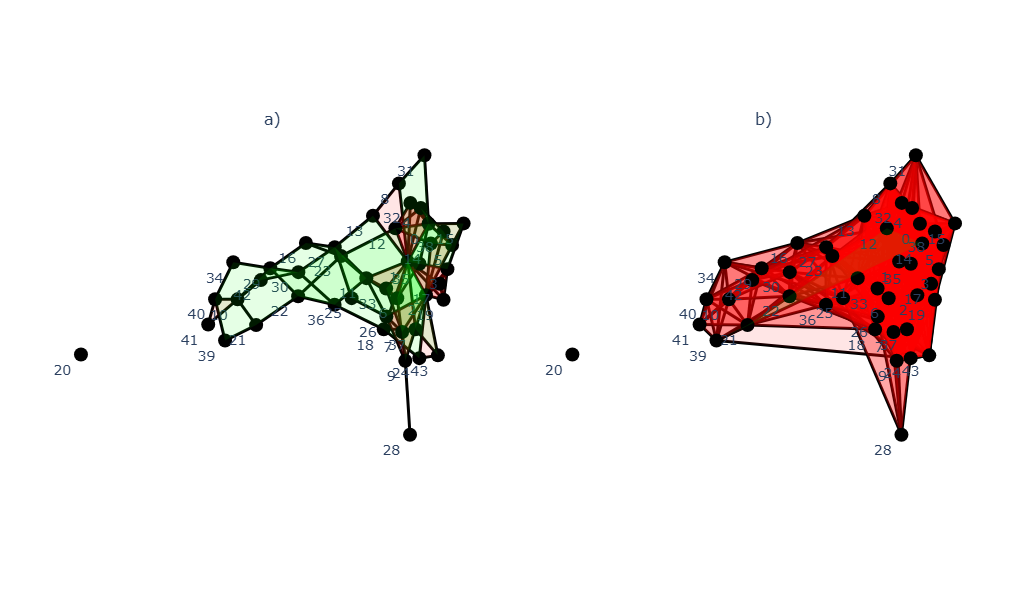

In [28]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Definir tamaño dinámico para los títulos y subtítulos
height = 600
width = 1000  # Ajusté el ancho para 2 subgráficos
font_size = int(height / 50)  # Ajustar tamaño de fuente proporcionalmente al alto de la figura

# Crear subgráficos en una fila
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('a)', 'b)'),
    horizontal_spacing=0.05,  # Espacio horizontal entre gráficos
    vertical_spacing=1
)


# Añadir las trazas de cada figura al subgráfico correspondiente
for trace in fig1.data:
    fig.add_trace(trace, row=1, col=1)
for trace in fig2.data:
    fig.add_trace(trace, row=1, col=2)

# Actualizar el diseño del gráfico
fig.update_layout(
    title_x=0.5,  # Centrar el título
    title_y=0.9,
    showlegend=False,  # Ocultar leyenda si no es necesaria
    height=height,        # Altura total del gráfico
    width=width,        # Ancho total del gráfico
    plot_bgcolor='white',  # Fondo blanco para toda la figura
    paper_bgcolor='white',  # Fondo blanco para el área de la figura
    xaxis=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    yaxis=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    xaxis2=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    yaxis2=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    font=dict(size=font_size),  # Ajustar tamaño de fuente proporcional
    title_font=dict(size=int(font_size * 3)),  # Ajustar título más grande proporcionalmente
    margin=dict(t=130, b=140, l=50, r=50),  # Ajustar márgenes para evitar que se encimen los títulos
)

# Guardar la figura en formato SVG sin mostrarla
fig.write_image("visual_complex_R5P_2_subplots.svg", format='svg')
fig

In [45]:
ciclos_info=resum.loc['R5P_AMINOACIDS','ciclos']

In [49]:
ciclos_info[1]

['Clavibacter michiganensis subsp. nebraskensis NCPPB 2581 NC_0208911',
 'Corynebacterium Sp. Jcb CBYN01',
 ['Corynebacterium Sp. Gd7 CAVS02',
  'Corynebacterium ureicelerivorans NZ_CP009215.1'],
 ['Rothia mucilaginosa ATCC 25296 ACVO01',
  'Corynebacterium massiliense dsm 45435 ATVG01',
  'Rothia mucilaginosa DY-18 NC_013715.1']]

In [46]:
df_cont_gen=pd.DataFrame()
df_cont_gen
for ciclo in ciclos_info:
    if type(ciclo)==str:
        df_cont_gen.loc

SyntaxError: unexpected EOF while parsing (222114447.py, line 1)

<h3>Género por R5P</h3>

In [25]:
R5P_df_by_genus_pathway,R5P_df_by_genus_pathway_drop_duplicate,R5P_representative_genomes_genus_pathway=get_df_by_genus_pathway(R5P_df_by_pathway,names)
R5P_complex_genus_pathways=get_complex_by_pathways(R5P_df_by_genus_pathway_drop_duplicate)

In [26]:
R5P_holes_genus_no_names,R5P_holes_genus_with_names,R5P_holes_genus_per_filt_lvl=get_holes_by_pathways(R5P_complex_genus_pathways,R5P_df_by_genus_pathway_drop_duplicate)

In [28]:
get_resum_df(R5P_df_by_genus_pathway,R5P_representative_genomes_genus_pathway,names,R5P_complex_genus_pathways,R5P_holes_genus_per_filt_lvl)

,num_columnas,num_hoyos,ciclos,ciclos por genero,duración hoyos
Serinicoccus_R5P_AMINOACIDS,9,0,[],[],[]
Ornithinimicrobium_R5P_AMINOACIDS,9,0,[],[],[]
